# Tarea 1 · Parte 2: Clasificación de noticias

| | |
|---|---|
| **Datos** | `datos/noticias.csv`: 401 titulares de **La República** (Perú), recolectados en la Parte 1 |
| **Etiquetas** | `politica`, `economia`, `deportes`, `ciencia_tecnologia` (≈100 por clase) |
| **Texto de entrada** | el **titular** (la misma entrada para los tres enfoques, para que la comparación sea justa) |

**Objetivo:** comparar tres formas de clasificar titulares en 4 categorías:

1. **Zero-shot** con un modelo NLI en español (sin entrenar nada).
2. **Supervisión débil con un LLM** (Gemini): el LLM etiqueta las noticias a partir de un prompt.
3. **Transformer fine-tuned** (`distilbert-base-multilingual-cased`) entrenado con las etiquetas del LLM.

**Plan del notebook**

| Paso | Qué se hace |
|---|---|
| 1 | Split estratificado 70/15/15 (`random_state=42`); el test queda aislado hasta el final |
| 2 | Baseline zero-shot sobre 40 titulares del test |
| 3 | Etiquetado de las 401 noticias con Gemini (prompt estructurado, JSON, lotes, caché) |
| 4 | Auditoría humana de 20 etiquetas del LLM |
| 5 | Fine-tuning de DistilBERT con las etiquetas del LLM |
| 6 | Evaluación final en test |
| 7 | Tabla comparativa y recomendación |

## 0. Configuración

- Todas las rutas son relativas a la carpeta `tarea_1/`.
- La llave de Gemini se lee de `tarea_1/.env` (variable `GEMINI_API_KEY`) con `python-dotenv`.
  **La llave nunca se imprime**: solo se muestra si se cargó o no. El archivo `.env` está en `.gitignore`.
- Se fijan semillas para que los resultados sean reproducibles.

In [1]:
import os, json, time, random, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from dotenv import load_dotenv
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 120)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DATOS = Path("datos")
MODELO_DIR = Path("modelo")
ETIQUETAS = ["politica", "economia", "deportes", "ciencia_tecnologia"]

load_dotenv(".env")
print("GEMINI_API_KEY cargada:", os.getenv("GEMINI_API_KEY") is not None)  # solo True/False, nunca la llave
print("torch", torch.__version__, "| GPU disponible:", torch.cuda.is_available())

df = pd.read_csv(DATOS / "noticias.csv")
df["id"] = range(len(df))  # identificador de fila (hay 1 titular repetido, así que no usamos el texto como clave)
print(df.shape)
df["etiqueta"].value_counts()

GEMINI_API_KEY cargada: True
torch 2.14.1+cpu | GPU disponible: False
(401, 8)


etiqueta
politica              101
deportes              100
ciencia_tecnologia    100
economia              100
Name: count, dtype: int64

## 1. Split estratificado 70 / 15 / 15

Se hace en dos pasos con `train_test_split(..., stratify=etiqueta, random_state=42)`:

1. 70 % **train** vs 30 % resto.
2. El 30 % se divide a la mitad: 15 % **validación** y 15 % **test**.

*Estratificado* significa que cada conjunto conserva la misma proporción de las 4 categorías.
El **test no se usa** para nada (ni para elegir prompts ni hiperparámetros) hasta la evaluación final del paso 6;
la única excepción, pedida por la tarea, es el baseline zero-shot, que no entrena ni ajusta nada.

In [2]:
train_df, resto_df = train_test_split(df, test_size=0.30, stratify=df["etiqueta"], random_state=SEED)
val_df, test_df = train_test_split(resto_df, test_size=0.50, stratify=resto_df["etiqueta"], random_state=SEED)

resumen_split = pd.DataFrame({
    "train": train_df["etiqueta"].value_counts(),
    "val": val_df["etiqueta"].value_counts(),
    "test": test_df["etiqueta"].value_counts(),
}).loc[ETIQUETAS]
resumen_split.loc["TOTAL"] = resumen_split.sum()
print(f"train={len(train_df)}  val={len(val_df)}  test={len(test_df)}  (total={len(train_df)+len(val_df)+len(test_df)})")
resumen_split

train=280  val=60  test=61  (total=401)


,train,val,test
etiqueta,,,
politica,70,15,16
economia,70,15,15
deportes,70,15,15
ciencia_tecnologia,70,15,15
TOTAL,280,60,61


## 2. Baseline zero-shot

Un modelo **zero-shot** clasifica sin haber visto ningún ejemplo etiquetado de nuestra tarea.
`Recognai/bert-base-spanish-wwm-cased-xnli` es un BERT en español entrenado en **NLI** (inferencia de lenguaje natural):
para cada titular arma la hipótesis *"Esta noticia trata sobre {categoría}."* con cada una de las 4 categorías,
y elige la que el modelo considera más "implicada" por el texto.

- Usamos nombres de categoría en lenguaje natural (`política`, `economía`, `deportes`, `ciencia y tecnología`) porque
  el modelo entiende mejor palabras reales que identificadores como `ciencia_tecnologia`; luego se mapean de vuelta.
- Se evalúan **40 titulares del test** elegidos al azar (`random_state=42`).
- Métricas: **accuracy** (proporción de aciertos) y **F1 macro** (promedio del F1 de cada clase, sin ponderar;
  castiga si alguna categoría se clasifica mal aunque las demás vayan bien).

In [3]:
from transformers import pipeline

zs = pipeline("zero-shot-classification", model="Recognai/bert-base-spanish-wwm-cased-xnli", device=-1)

NOMBRES_ZS = {"política": "politica", "economía": "economia",
              "deportes": "deportes", "ciencia y tecnología": "ciencia_tecnologia"}
PLANTILLA = "Esta noticia trata sobre {}."

zs_df = test_df.sample(40, random_state=SEED).copy()

t0 = time.perf_counter()
salidas = zs(zs_df["titular"].tolist(), candidate_labels=list(NOMBRES_ZS), hypothesis_template=PLANTILLA)
t_zs = time.perf_counter() - t0

zs_df["pred_zs"] = [NOMBRES_ZS[s["labels"][0]] for s in salidas]
zs_df["score_zs"] = [round(s["scores"][0], 3) for s in salidas]

acc_zs = accuracy_score(zs_df["etiqueta"], zs_df["pred_zs"])
f1_zs = f1_score(zs_df["etiqueta"], zs_df["pred_zs"], average="macro")
lat_zs = 1000 * t_zs / len(zs_df)
print(f"Zero-shot (n=40)  accuracy={acc_zs:.3f}  F1 macro={f1_zs:.3f}  latencia≈{lat_zs:.0f} ms/titular (CPU)")
print(zs_df["etiqueta"].value_counts().to_dict())

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Zero-shot (n=40)  accuracy=0.650  F1 macro=0.577  latencia≈356 ms/titular (CPU)
{'ciencia_tecnologia': 11, 'politica': 11, 'economia': 9, 'deportes': 9}


In [4]:
print(classification_report(zs_df["etiqueta"], zs_df["pred_zs"], labels=ETIQUETAS, zero_division=0))
zs_df.loc[zs_df["pred_zs"] != zs_df["etiqueta"], ["titular", "etiqueta", "pred_zs", "score_zs"]]

                    precision    recall  f1-score   support

          politica       0.48      0.91      0.62        11
          economia       0.00      0.00      0.00         9
          deportes       0.90      1.00      0.95         9
ciencia_tecnologia       0.88      0.64      0.74        11

          accuracy                           0.65        40
         macro avg       0.56      0.64      0.58        40
      weighted avg       0.57      0.65      0.59        40



,titular,etiqueta,pred_zs,score_zs
330,"Gobierno pide crédito suplementario por S/8.228 millones: aviones caza, pensiones, seguridad, salud y FEN",economia,ciencia_tecnologia,0.336
124,López Chau retoma propuesta de fondo soberano de riqueza para financiar la industrialización del Perú,economia,politica,0.406
82,Frente a las costas de Alaska deriva desde 1931 un barco fantasma de 1322 toneladas que nadie logró traer de vuelta ...,ciencia_tecnologia,politica,0.270
365,Aeropuerto Jorge Chávez: LAP revela que aerolíneas aún no aceptan reducción de la TUUA de transferencia internacional,economia,politica,0.311
228,"Precio del dólar hoy en Perú, jueves 8 de octubre: consulta el tipo de cambio para compra y venta",economia,politica,0.385
129,"Chats de los asesinos de “China Polo”: “Si no la matas tú, la mato yo”",politica,deportes,0.811
10,"Precio del dólar hoy en Perú, sábado 17 de octubre: consulta el tipo de cambio para compra y venta",economia,politica,0.381
307,"Precio del dólar hoy en Perú, domingo 4 de octubre: consulta el tipo de cambio para compra y venta",economia,politica,0.430
308,"Los primeros pobladores de América llegaron durante el periodo más frío de la última era glacial, según estudio de ADN",ciencia_tecnologia,politica,0.302
54,"Precio del dólar hoy en Perú, jueves 15 de octubre: consulta el tipo de cambio para compra y venta",economia,politica,0.390


**Lectura:** la tabla de arriba lista los errores del zero-shot. El modelo no conoce el contexto peruano
(nombres de clubes, instituciones, políticos), por lo que depende solo de pistas léxicas generales del titular.
Este resultado sirve como **piso**: cualquier enfoque más costoso debería superarlo.

## 3. Supervisión débil con un LLM (Gemini)

**Idea:** en vez de etiquetar a mano, le pedimos a un LLM que etiquete las 401 noticias. Esas etiquetas son
*débiles* (pueden tener errores), pero son baratas y rápidas de obtener, y luego sirven para entrenar un modelo propio.

**Cómo se hace:**

- Modelo: **`gemini-3.8-flash`**, el modelo *flash* disponible en el plan gratuito de la llave
  (`gemini-2.5-flash` ya no está disponible para cuentas nuevas).
- **Prompt estructurado** (visible en la celda siguiente): rol, definición de cada categoría con ejemplos de temas,
  reglas de desempate y formato de salida obligatorio.
- **Salida en JSON**: se fuerza con `response_mime_type="application/json"` y un **esquema** (`response_schema`),
  de modo que cada respuesta trae `id`, `etiqueta` (solo una de las 4 permitidas) y `confianza` (0 a 1).
- **Lotes y pausas:** se envían 25 titulares por llamada (17 llamadas en total) con una pausa de 6 s entre llamadas,
  y reintentos con espera creciente si la API devuelve error de cuota (429), para respetar el límite gratuito.
- **Temperatura 0** para respuestas lo más deterministas posible.
- **Caché:** cada lote terminado se guarda en `datos/etiquetas_llm_parcial.json`; al terminar se escribe
  `datos/etiquetas_llm.csv`. Si el CSV ya existe, **no se vuelve a llamar a la API** (re-ejecutar el notebook es gratis).
- Al LLM solo se le envía el **titular** (no la etiqueta original, ni la sección, ni la URL), para que no "haga trampa".

In [5]:
MODELO_LLM = "gemini-3.8-flash"
TAM_LOTE = 25
PAUSA_S = 6

PROMPT_SISTEMA = """Eres un editor de un diario peruano que clasifica noticias por sección.
Recibirás una lista de titulares de noticias de La República (Perú), cada uno con un id.
Asigna a cada titular EXACTAMENTE UNA de estas 4 categorías:

- politica: gobierno, Congreso, partidos, elecciones, candidatos, ministros, Poder Judicial, Fiscalía,
  corrupción, política internacional y relaciones entre Estados.
- economia: mercados, tipo de cambio, precios, inflación, empleo, empresas, impuestos, comercio, consumo,
  bonos y pagos estatales, AFP, finanzas personales, minería y energía como actividad económica.
- deportes: fútbol y cualquier otra disciplina deportiva, clubes, selecciones, atletas, torneos, resultados,
  fichajes y transmisiones de partidos.
- ciencia_tecnologia: investigación científica, salud y medicina basadas en estudios, espacio y astronomía,
  medio ambiente y clima, animales y naturaleza, tecnología, internet, inteligencia artificial, celulares,
  aplicaciones, videojuegos y empresas tecnológicas.

Reglas:
1. Elige la categoría del TEMA PRINCIPAL del titular, no la de una palabra suelta.
2. Si un titular mezcla temas (p. ej., un político hablando de economía), elige el foco principal de la noticia.
3. "confianza" es tu probabilidad (entre 0 y 1) de que la etiqueta sea correcta. Usa valores bajos si dudas.
4. Devuelve un objeto por cada titular recibido, con el mismo id, y nada más.

Formato de salida (JSON):
[{"id": <int>, "etiqueta": "<politica|economia|deportes|ciencia_tecnologia>", "confianza": <float 0-1>}, ...]"""

def armar_mensaje(lote):
    """lote: lista de (id, titular) -> texto del usuario."""
    lineas = [f'{i}: "{t}"' for i, t in lote]
    return "Clasifica estos titulares:\n" + "\n".join(lineas)

print(PROMPT_SISTEMA)
print("\n--- Ejemplo de mensaje de usuario (primeros 3 titulares) ---")
print(armar_mensaje(list(zip(df["id"][:3], df["titular"][:3]))))

Eres un editor de un diario peruano que clasifica noticias por sección.
Recibirás una lista de titulares de noticias de La República (Perú), cada uno con un id.
Asigna a cada titular EXACTAMENTE UNA de estas 4 categorías:

- politica: gobierno, Congreso, partidos, elecciones, candidatos, ministros, Poder Judicial, Fiscalía,
  corrupción, política internacional y relaciones entre Estados.
- economia: mercados, tipo de cambio, precios, inflación, empleo, empresas, impuestos, comercio, consumo,
  bonos y pagos estatales, AFP, finanzas personales, minería y energía como actividad económica.
- deportes: fútbol y cualquier otra disciplina deportiva, clubes, selecciones, atletas, torneos, resultados,
  fichajes y transmisiones de partidos.
- ciencia_tecnologia: investigación científica, salud y medicina basadas en estudios, espacio y astronomía,
  medio ambiente y clima, animales y naturaleza, tecnología, internet, inteligencia artificial, celulares,
  aplicaciones, videojuegos y empresas tec

In [6]:
RUTA_LLM = DATOS / "etiquetas_llm.csv"
RUTA_PARCIAL = DATOS / "etiquetas_llm_parcial.json"
RUTA_META = DATOS / "etiquetas_llm_meta.json"

def etiquetar_con_gemini(df):
    from google import genai
    from google.genai import types

    cliente = genai.Client(api_key=os.getenv("GEMINI_API_KEY"))
    esquema = {
        "type": "ARRAY",
        "items": {
            "type": "OBJECT",
            "properties": {
                "id": {"type": "INTEGER"},
                "etiqueta": {"type": "STRING", "enum": ETIQUETAS},
                "confianza": {"type": "NUMBER"},
            },
            "required": ["id", "etiqueta", "confianza"],
        },
    }
    config = types.GenerateContentConfig(
        system_instruction=PROMPT_SISTEMA, temperature=0,
        response_mime_type="application/json", response_schema=esquema,
    )

    hechos = json.loads(RUTA_PARCIAL.read_text(encoding="utf-8")) if RUTA_PARCIAL.exists() else {}
    pendientes = [(i, t) for i, t in zip(df["id"], df["titular"]) if str(i) not in hechos]
    lotes = [pendientes[k:k + TAM_LOTE] for k in range(0, len(pendientes), TAM_LOTE)]
    print(f"Ya en caché: {len(hechos)} | pendientes: {len(pendientes)} en {len(lotes)} lotes")

    llamadas, t_api = 0, 0.0
    for n, lote in enumerate(lotes, 1):
        ids_lote = {i for i, _ in lote}
        for intento in range(5):
            try:
                t0 = time.perf_counter()
                r = cliente.models.generate_content(model=MODELO_LLM, contents=armar_mensaje(lote), config=config)
                t_api += time.perf_counter() - t0; llamadas += 1
                items = json.loads(r.text)
                validos = {it["id"]: it for it in items if it["id"] in ids_lote and it["etiqueta"] in ETIQUETAS}
                if set(validos) != ids_lote:
                    raise ValueError(f"faltan ids: {sorted(ids_lote - set(validos))}")
                break
            except Exception as e:
                espera = 20 * (intento + 1)
                print(f"  lote {n}: intento {intento + 1} falló ({type(e).__name__}); reintento en {espera}s")
                time.sleep(espera)
        else:
            raise RuntimeError(f"El lote {n} falló 5 veces; vuelve a ejecutar la celda (la caché conserva lo avanzado).")

        fecha = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
        for i, it in validos.items():
            hechos[str(i)] = {"etiqueta_llm": it["etiqueta"],
                              "confianza": round(float(it["confianza"]), 3), "fecha": fecha}
        RUTA_PARCIAL.write_text(json.dumps(hechos, ensure_ascii=False, indent=1), encoding="utf-8")
        print(f"  lote {n}/{len(lotes)} ok ({len(validos)} titulares)")
        if n < len(lotes):
            time.sleep(PAUSA_S)

    meta = {"modelo_llm": MODELO_LLM, "llamadas": llamadas, "titulares": len(df), "tam_lote": TAM_LOTE,
            "segundos_api": round(t_api, 1), "ms_por_titular": round(1000 * t_api / max(len(pendientes), 1), 1)}
    RUTA_META.write_text(json.dumps(meta, indent=1), encoding="utf-8")

    salida = pd.DataFrame({
        "titular": df["titular"].values,
        "etiqueta_llm": [hechos[str(i)]["etiqueta_llm"] for i in df["id"]],
        "confianza": [hechos[str(i)]["confianza"] for i in df["id"]],
        "modelo_llm": MODELO_LLM,
        "fecha": [hechos[str(i)]["fecha"] for i in df["id"]],
    })
    salida.to_csv(RUTA_LLM, index=False, encoding="utf-8")
    return salida

if RUTA_LLM.exists():
    print(f"Caché encontrada: se carga {RUTA_LLM} y NO se llama a la API.")
    llm = pd.read_csv(RUTA_LLM)
else:
    llm = etiquetar_con_gemini(df)

assert len(llm) == len(df)
meta_llm = json.loads(RUTA_META.read_text(encoding="utf-8"))
print(meta_llm)
llm.head()

Caché encontrada: se carga datos\etiquetas_llm.csv y NO se llama a la API.
{'modelo_llm': 'gemini-3.8-flash', 'llamadas': 17, 'titulares': 401, 'tam_lote': 25, 'segundos_api': 149.2, 'ms_por_titular': 372.0}


,titular,etiqueta_llm,confianza,modelo_llm,fecha
0,Alianza Lima se hizo fuerte en Matute: venció 3-1 a Atlético Grau y se mantiene en la lucha por el Torneo Clausura d...,deportes,0.99,gemini-3.8-flash,2026-10-18 11:45:42
1,Tabla de posiciones Torneo Clausura y Acumulado de la Liga 1 2026: resultados de los partidos de la fecha 12,deportes,0.99,gemini-3.8-flash,2026-10-18 11:45:42
2,¡Rugieron Las Pumas! Universitario venció 3-0 a Deportivo Soan y empieza con pie derecho la Liga Peruana de Vóley 20...,deportes,0.99,gemini-3.8-flash,2026-10-18 11:45:42
3,Científicos demuestran que un breve contacto físico entre corales sanos y blanqueados puede ayudarles a restaurar el...,ciencia_tecnologia,0.99,gemini-3.8-flash,2026-10-18 11:45:42
4,El Reino Unido pondrá en marcha la primera garra robótica del mundo para recolectar la basura espacial que rodea a l...,ciencia_tecnologia,0.99,gemini-3.8-flash,2026-10-18 11:45:42


El CSV `datos/etiquetas_llm.csv` tiene las columnas pedidas (`titular, etiqueta_llm, confianza, modelo_llm, fecha`)
y está **en el mismo orden de filas** que `noticias.csv`, por lo que se une por posición (columna `id`).

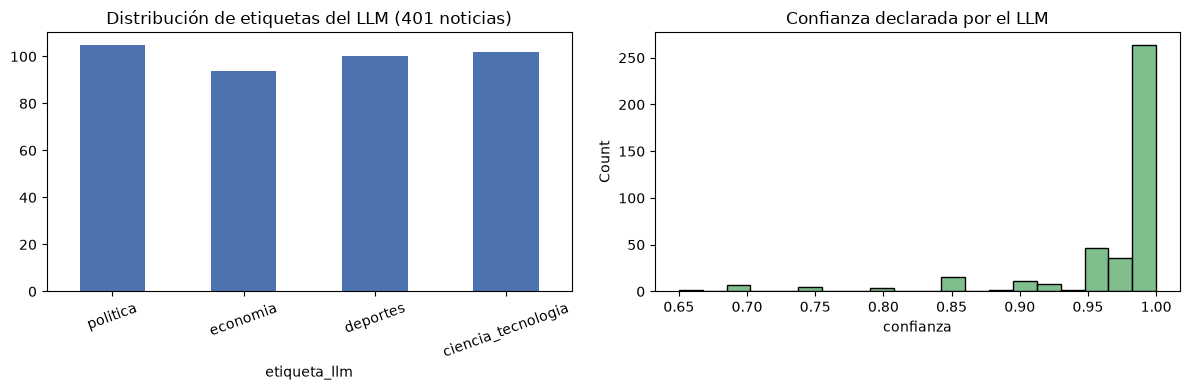

Confianza media: 0.963 | con confianza < 0.8: 14


In [7]:
df["etiqueta_llm"] = llm["etiqueta_llm"].values
df["confianza"] = llm["confianza"].values
for parte in (train_df, val_df, test_df, zs_df):
    parte["etiqueta_llm"] = df.loc[parte.index, "etiqueta_llm"]
    parte["confianza"] = df.loc[parte.index, "confianza"]

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
df["etiqueta_llm"].value_counts().reindex(ETIQUETAS).plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set_title("Distribución de etiquetas del LLM (401 noticias)"); ax[0].tick_params(axis="x", rotation=20)
sns.histplot(df["confianza"], bins=20, ax=ax[1], color="#55A868")
ax[1].set_title("Confianza declarada por el LLM"); ax[1].set_xlabel("confianza")
plt.tight_layout(); plt.show()

print("Confianza media:", round(df["confianza"].mean(), 3), "| con confianza < 0.8:", (df["confianza"] < 0.8).sum())

**Coincidencia del LLM con la etiqueta original.** La columna `etiqueta` viene de la sección del diario
(Parte 1), así que la usamos como referencia. Mostramos la coincidencia en train+val (los datos de trabajo);
la del test se reporta recién en el paso 6.

In [8]:
trabajo = pd.concat([train_df, val_df])
print(f"LLM vs etiqueta original en train+val (n={len(trabajo)}): "
      f"accuracy={accuracy_score(trabajo['etiqueta'], trabajo['etiqueta_llm']):.3f}  "
      f"F1 macro={f1_score(trabajo['etiqueta'], trabajo['etiqueta_llm'], average='macro'):.3f}")
pd.crosstab(trabajo["etiqueta"], trabajo["etiqueta_llm"], rownames=["original"], colnames=["LLM"]).loc[ETIQUETAS, ETIQUETAS]

LLM vs etiqueta original en train+val (n=340): accuracy=0.982  F1 macro=0.982


LLM,politica,economia,deportes,ciencia_tecnologia
original,,,,
politica,84,1,0,0
economia,4,80,0,1
deportes,0,0,85,0
ciencia_tecnologia,0,0,0,85


## 4. Auditoría humana de las etiquetas del LLM

Se eligen **20 predicciones al azar** (`random_state=42`) entre las 401 y una persona revisa, leyendo solo el titular,
si la etiqueta del LLM es correcta. Así medimos la calidad de la supervisión débil con un criterio humano
(independiente de la sección del diario).

In [9]:
auditoria = df.sample(20, random_state=SEED)[["id", "titular", "etiqueta_llm", "confianza"]].reset_index(drop=True)
auditoria.index = auditoria.index + 1
auditoria

,id,titular,etiqueta_llm,confianza
1,285,Ignacio Buse rumbo a un partido histórico: qué debe pasar para enfrentar al español Carlos Alcaraz en el Masters 100...,deportes,0.99
2,281,"Lionel Messi en el día de su despedida de la selección argentina: ""Llegó el momento, me voy en paz""",deportes,0.99
3,33,Un trineo de nieve diseñado en España y propulsado por 20 cometas cruzará la Antártida en un viaje de 80 días con ca...,ciencia_tecnologia,0.95
4,211,"Paolo Guerrero podría afrontar juicio penal por el caso de los diplomas falsos, advierte abogado",deportes,0.75
5,93,"Vocero de la Diócesis de Chiclayo ante posible cancelación de viajes del papa León XIV: ""Hay que primar la salud""",politica,0.70
6,84,"Un planeta del tamaño de la Tierra, similar a los de Star Wars, podría sobrevivir con 2 soles a tan solo 16 años luz",ciencia_tecnologia,0.99
7,390,Inteligencia artificial para conseguir trabajo: estas herramientas pueden reducir hasta 30% la búsqueda laboral,ciencia_tecnologia,0.85
8,94,Liga Nacional de Basketball 2026: Líbero transmitirá los partidos en vivo por YouTube,deportes,0.99
9,225,"Gasolina en Perú: precio subió 40,6% en un año y el petróleo supera los US$105 por barril",economia,0.99
10,126,"Programación fecha 12 Torneo Clausura 2026: día, hora y canal dónde ver los partidos de la Liga 1",deportes,1.00


### Resultado de la revisión manual

Leí los 20 titulares y marqué si la etiqueta del LLM es correcta:

- **Caso 4** (*Paolo Guerrero podría afrontar juicio penal…*) → **correcto (deportes)**. Aunque el tema es judicial,
  el protagonista es un futbolista y la noticia es de interés deportivo.
- **Caso 5** (*Vocero de la Diócesis de Chiclayo ante posible cancelación de viajes del papa León XIV…*) → **incorrecto**.
  Es una noticia religiosa sobre la salud del papa, **no es política**; en realidad no encaja en ninguna de las 4
  categorías. Es el *ruido* de la sección política que ya vimos en la Parte 1 (el diario publica en "política"
  noticias que no lo son). **No se fuerza ni se inventa una quinta categoría**: se registra como desacuerdo y se
  anota como limitación del dataset.
- Los otros 18 casos → correctos.

In [10]:
incorrectos = {5: "Noticia religiosa (salud del papa); no encaja en ninguna de las 4 categorías: ruido de la sección política"}
notas = {4: "Tema judicial, pero el protagonista es un futbolista: noticia de interés deportivo"}

auditoria["correcto_humano"] = [i not in incorrectos for i in auditoria.index]
auditoria["nota"] = [incorrectos.get(i, notas.get(i, "")) for i in auditoria.index]

acuerdo = auditoria["correcto_humano"].mean()
print(f"Acuerdo humano-LLM: {auditoria['correcto_humano'].sum()}/{len(auditoria)} = {acuerdo:.0%}")
auditoria[["titular", "etiqueta_llm", "confianza", "correcto_humano", "nota"]]

Acuerdo humano-LLM: 19/20 = 95%


,titular,etiqueta_llm,confianza,correcto_humano,nota
1,Ignacio Buse rumbo a un partido histórico: qué debe pasar para enfrentar al español Carlos Alcaraz en el Masters 100...,deportes,0.99,True,
2,"Lionel Messi en el día de su despedida de la selección argentina: ""Llegó el momento, me voy en paz""",deportes,0.99,True,
3,Un trineo de nieve diseñado en España y propulsado por 20 cometas cruzará la Antártida en un viaje de 80 días con ca...,ciencia_tecnologia,0.95,True,
4,"Paolo Guerrero podría afrontar juicio penal por el caso de los diplomas falsos, advierte abogado",deportes,0.75,True,"Tema judicial, pero el protagonista es un futbolista: noticia de interés deportivo"
5,"Vocero de la Diócesis de Chiclayo ante posible cancelación de viajes del papa León XIV: ""Hay que primar la salud""",politica,0.70,False,Noticia religiosa (salud del papa); no encaja en ninguna de las 4 categorías: ruido de la sección política
6,"Un planeta del tamaño de la Tierra, similar a los de Star Wars, podría sobrevivir con 2 soles a tan solo 16 años luz",ciencia_tecnologia,0.99,True,
7,Inteligencia artificial para conseguir trabajo: estas herramientas pueden reducir hasta 30% la búsqueda laboral,ciencia_tecnologia,0.85,True,
8,Liga Nacional de Basketball 2026: Líbero transmitirá los partidos en vivo por YouTube,deportes,0.99,True,
9,"Gasolina en Perú: precio subió 40,6% en un año y el petróleo supera los US$105 por barril",economia,0.99,True,
10,"Programación fecha 12 Torneo Clausura 2026: día, hora y canal dónde ver los partidos de la Liga 1",deportes,1.00,True,


**Conclusión de la auditoría:** el acuerdo es **95 % (19/20)**. El único desacuerdo no es un error de criterio del
LLM sino una noticia fuera del alcance de las 4 categorías; el LLM lo "sabía" en parte, porque le asignó una de las
confianzas más bajas de la muestra (0.70). Esto respalda usar las etiquetas del LLM como supervisión débil.

**Limitación del dataset:** algunas noticias de la sección política (religión, sucesos policiales, etc.) no
pertenecen a ninguna de las 4 categorías. Como el esquema es cerrado, cualquier clasificador está obligado a
asignarles una etiqueta que no les corresponde.

## 5. Fine-tuning de `distilbert-base-multilingual-cased` con supervisión débil

**Qué es:** DistilBERT multilingüe es una versión reducida de BERT (≈135 M de parámetros) que entiende español.
Le agregamos una capa de clasificación de 4 salidas y la **entrenamos** (ajustamos sus pesos) con nuestros titulares.

**Decisión clave — con qué etiquetas entrenar y con cuáles evaluar:**

| Conjunto | Etiqueta usada | Por qué |
|---|---|---|
| **train** (280) | `etiqueta_llm` (Gemini) | Simula el caso real: **no tenemos etiquetas humanas**, solo las del LLM. Es la *supervisión débil*. |
| **val** (60) | `etiqueta` original | Medimos cada época contra la "verdad" de referencia, no contra el propio LLM. |
| **test** (61) | `etiqueta` original | Evaluación final honesta, sobre datos nunca vistos. |

Así el experimento responde la pregunta práctica: *¿se puede obtener un buen clasificador propio sin etiquetar a mano,
usando un LLM como "anotador"?* Si evaluáramos contra las etiquetas del LLM solo mediríamos cuánto imita al LLM,
incluidos sus errores. (En nuestro dataset la sección del diario existe, pero en un caso real normalmente no la
tendríamos; por eso no la usamos para entrenar.)

**Configuración** (la pedida por la tarea): 3 épocas, batch size 16, evaluación al final de cada época con
**F1 macro** (`sklearn.metrics.f1_score(average="macro")`), learning rate 5e-5, `seed=42`, titulares truncados a
64 tokens (el más largo tiene 165 caracteres). Se entrena en **CPU**.

In [11]:
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, set_seed)

set_seed(SEED)
BASE = "distilbert-base-multilingual-cased"
label2id = {e: i for i, e in enumerate(ETIQUETAS)}
id2label = {i: e for e, i in label2id.items()}

tokenizer = AutoTokenizer.from_pretrained(BASE)
modelo = AutoModelForSequenceClassification.from_pretrained(
    BASE, num_labels=len(ETIQUETAS), id2label=id2label, label2id=label2id)

class Titulares(torch.utils.data.Dataset):
    def __init__(self, textos, etiquetas):
        self.enc = tokenizer(list(textos), truncation=True, max_length=64, padding="max_length")
        self.y = [label2id[e] for e in etiquetas]
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        item = {k: torch.tensor(v[i]) for k, v in self.enc.items()}
        item["labels"] = torch.tensor(self.y[i])
        return item

ds_train = Titulares(train_df["titular"], train_df["etiqueta_llm"])  # supervisión débil (LLM)
ds_val = Titulares(val_df["titular"], val_df["etiqueta"])            # referencia original
ds_test = Titulares(test_df["titular"], test_df["etiqueta"])         # referencia original

def calcular_metricas(pred):
    y_pred = pred.predictions.argmax(-1)
    return {"accuracy": accuracy_score(pred.label_ids, y_pred),
            "f1_macro": f1_score(pred.label_ids, y_pred, average="macro")}

args = TrainingArguments(
    output_dir="entrenamiento_tmp", num_train_epochs=3,
    per_device_train_batch_size=16, per_device_eval_batch_size=32,
    learning_rate=5e-5, eval_strategy="epoch", logging_strategy="epoch",
    save_strategy="no", seed=SEED, report_to="none", disable_tqdm=True,
)
trainer = Trainer(model=modelo, args=args, train_dataset=ds_train, eval_dataset=ds_val,
                  compute_metrics=calcular_metricas)

t0 = time.perf_counter()
trainer.train()
print(f"Tiempo de entrenamiento: {time.perf_counter() - t0:.0f} s en CPU")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-multilingual-cased
Key                     | Status     | 
------------------------+------------+-
vocab_layer_norm.weight | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
classifier.weight       | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


{'loss': '1.059', 'grad_norm': '4.415', 'learning_rate': '3.426e-05', 'epoch': '1'}


{'eval_loss': '0.5282', 'eval_accuracy': '0.95', 'eval_f1_macro': '0.9499', 'eval_runtime': '3.21', 'eval_samples_per_second': '18.69', 'eval_steps_per_second': '0.623', 'epoch': '1'}


{'loss': '0.3326', 'grad_norm': '1.039', 'learning_rate': '1.759e-05', 'epoch': '2'}


{'eval_loss': '0.2446', 'eval_accuracy': '0.9333', 'eval_f1_macro': '0.9342', 'eval_runtime': '3.084', 'eval_samples_per_second': '19.46', 'eval_steps_per_second': '0.649', 'epoch': '2'}


{'loss': '0.1262', 'grad_norm': '0.6516', 'learning_rate': '9.259e-07', 'epoch': '3'}


{'eval_loss': '0.1882', 'eval_accuracy': '0.95', 'eval_f1_macro': '0.9505', 'eval_runtime': '3.047', 'eval_samples_per_second': '19.69', 'eval_steps_per_second': '0.656', 'epoch': '3'}
{'train_runtime': '180.4', 'train_samples_per_second': '4.656', 'train_steps_per_second': '0.299', 'train_loss': '0.5059', 'epoch': '3'}
Tiempo de entrenamiento: 181 s en CPU


,epoch,eval_loss,eval_accuracy,eval_f1_macro,train_loss
0,1.0,0.5282,0.9500,0.9499,1.0588
1,2.0,0.2446,0.9333,0.9342,0.3326
2,3.0,0.1882,0.9500,0.9505,0.1262


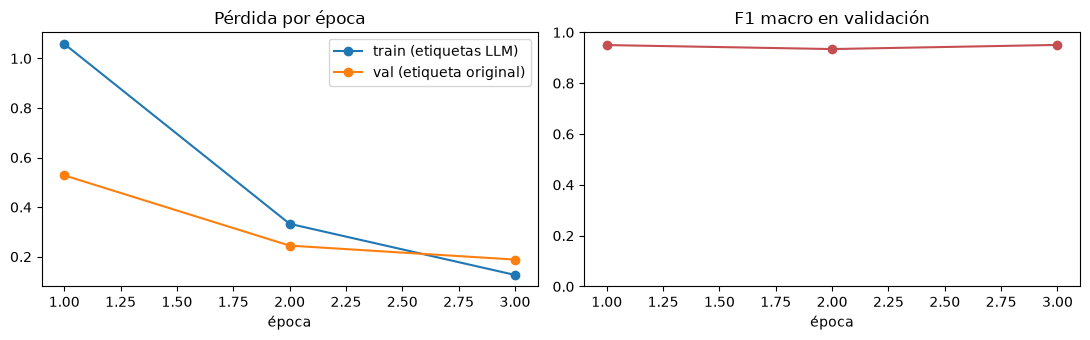

In [12]:
hist = pd.DataFrame(trainer.state.log_history)
por_epoca = (hist.dropna(subset=["eval_f1_macro"])[["epoch", "eval_loss", "eval_accuracy", "eval_f1_macro"]]
             .merge(hist.dropna(subset=["loss"])[["epoch", "loss"]], on="epoch")
             .rename(columns={"loss": "train_loss"}).round(4))
display(por_epoca)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(por_epoca["epoch"], por_epoca["train_loss"], "o-", label="train (etiquetas LLM)")
ax[0].plot(por_epoca["epoch"], por_epoca["eval_loss"], "o-", label="val (etiqueta original)")
ax[0].set_title("Pérdida por época"); ax[0].set_xlabel("época"); ax[0].legend()
ax[1].plot(por_epoca["epoch"], por_epoca["eval_f1_macro"], "o-", color="#C44E52")
ax[1].set_ylim(0, 1); ax[1].set_title("F1 macro en validación"); ax[1].set_xlabel("época")
plt.tight_layout(); plt.show()

In [13]:
trainer.save_model(str(MODELO_DIR))
tokenizer.save_pretrained(str(MODELO_DIR))
import shutil; shutil.rmtree("entrenamiento_tmp", ignore_errors=True)
for f in sorted(MODELO_DIR.iterdir()):
    print(f"{f.name:28s} {f.stat().st_size / 1e6:8.2f} MB")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

.gitkeep                         0.00 MB
config.json                      0.00 MB
model.safetensors              541.32 MB
tokenizer.json                   2.92 MB
tokenizer_config.json            0.00 MB
training_args.bin                0.01 MB


El modelo quedó en `modelo/`. Los pesos (`model.safetensors`, ≈540 MB) y `training_args.bin` están en
`.gitignore` y **no se suben a GitHub**; sí se suben `config.json` y los archivos del tokenizer (livianos).

## 6. Evaluación final en test

Ahora sí se usa el conjunto de **test** (61 noticias), comparando contra la etiqueta original.

In [14]:
t0 = time.perf_counter()
pred_test = trainer.predict(ds_test)
t_ft_lote = time.perf_counter() - t0
test_df["pred_ft"] = [id2label[i] for i in pred_test.predictions.argmax(-1)]

# latencia "en línea": un titular a la vez, como en una aplicación
modelo.eval()
t0 = time.perf_counter()
with torch.no_grad():
    for t in test_df["titular"]:
        modelo(**tokenizer(t, return_tensors="pt", truncation=True, max_length=64))
lat_ft = 1000 * (time.perf_counter() - t0) / len(test_df)

acc_ft = accuracy_score(test_df["etiqueta"], test_df["pred_ft"])
f1_ft = f1_score(test_df["etiqueta"], test_df["pred_ft"], average="macro")
print(f"Fine-tuned (test, n={len(test_df)})  accuracy={acc_ft:.3f}  F1 macro={f1_ft:.3f}")
print(f"Latencia CPU: {lat_ft:.0f} ms/titular (uno a uno) | {1000 * t_ft_lote / len(test_df):.0f} ms/titular (en lote)\n")
print(classification_report(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS, digits=3, zero_division=0))

Fine-tuned (test, n=61)  accuracy=0.918  F1 macro=0.920
Latencia CPU: 56 ms/titular (uno a uno) | 50 ms/titular (en lote)

                    precision    recall  f1-score   support

          politica      0.875     0.875     0.875        16
          economia      0.812     0.867     0.839        15
          deportes      1.000     1.000     1.000        15
ciencia_tecnologia      1.000     0.933     0.966        15

          accuracy                          0.918        61
         macro avg      0.922     0.919     0.920        61
      weighted avg      0.921     0.918     0.919        61



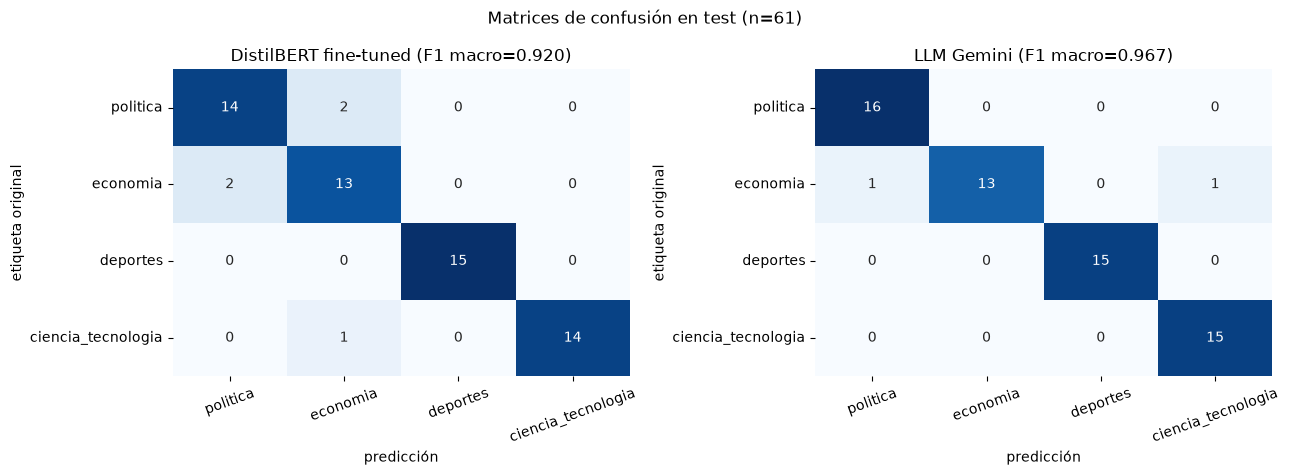

In [15]:
acc_llm = accuracy_score(test_df["etiqueta"], test_df["etiqueta_llm"])
f1_llm = f1_score(test_df["etiqueta"], test_df["etiqueta_llm"], average="macro")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
for a, col, titulo in [(ax[0], "pred_ft", f"DistilBERT fine-tuned (F1 macro={f1_ft:.3f})"),
                       (ax[1], "etiqueta_llm", f"LLM Gemini (F1 macro={f1_llm:.3f})")]:
    cm = confusion_matrix(test_df["etiqueta"], test_df[col], labels=ETIQUETAS)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a,
                xticklabels=ETIQUETAS, yticklabels=ETIQUETAS)
    a.set_xlabel("predicción"); a.set_ylabel("etiqueta original"); a.set_title(titulo)
    a.tick_params(axis="x", rotation=20)
plt.suptitle("Matrices de confusión en test (n=61)"); plt.tight_layout(); plt.show()

In [16]:
errores = test_df.loc[(test_df["pred_ft"] != test_df["etiqueta"]) | (test_df["etiqueta_llm"] != test_df["etiqueta"]),
                      ["titular", "etiqueta", "etiqueta_llm", "pred_ft"]]
print(f"Titulares de test con algún error ({len(errores)}):")
errores

Titulares de test con algún error (7):


,titular,etiqueta,etiqueta_llm,pred_ft
23,Produce cierra el 2026 sin segunda temporada de anchoveta y la SNP pide apoyo al Gobierno,economia,economia,politica
11,Fiscalía pide crédito suplementario al Congreso para pagar sueldos de fiscales en noviembre y diciembre,politica,politica,economia
347,Joven de 18 años analiza más de 5.000 noticias con la IA de OpenAI y gana US$175.000 por revelar sesgos raciales en ...,ciencia_tecnologia,ciencia_tecnologia,economia
220,"Crédito suplementario: congresistas cuestionan gasto en aviones F-16, endeudamiento y recursos para el sur",economia,politica,economia
390,Inteligencia artificial para conseguir trabajo: estas herramientas pueden reducir hasta 30% la búsqueda laboral,economia,ciencia_tecnologia,economia
396,Elmer Cuba: MEF llevará reformas económicas al Congreso si no obtiene facultades legislativas,economia,economia,politica
65,"Solo el 28.3% aprueba la gestión de Keiko Fujimori: su aceptación cayó 14.5% en un mes, según Bloomberg",politica,politica,economia


In [17]:
f1_por_clase = pd.DataFrame({
    "zero-shot (n=40)": f1_score(zs_df["etiqueta"], zs_df["pred_zs"], labels=ETIQUETAS, average=None, zero_division=0),
    "LLM (n=61)": f1_score(test_df["etiqueta"], test_df["etiqueta_llm"], labels=ETIQUETAS, average=None, zero_division=0),
    "fine-tuned (n=61)": f1_score(test_df["etiqueta"], test_df["pred_ft"], labels=ETIQUETAS, average=None, zero_division=0),
}, index=ETIQUETAS).round(3)
f1_por_clase

,zero-shot (n=40),LLM (n=61),fine-tuned (n=61)
politica,0.625,0.970,0.875
economia,0.000,0.929,0.839
deportes,0.947,1.000,1.000
ciencia_tecnologia,0.737,0.968,0.966


### Reflexión por categoría

- **Mejor: `deportes`** (F1 = 1.00 en el fine-tuned y en el LLM; 0.95 incluso en el zero-shot). Su vocabulario es
  muy propio y no se cruza con las otras secciones: nombres de clubes y jugadores, *Liga 1*, *Torneo Clausura*,
  *partido*, *fecha*, *goles*, *dónde ver*. Basta con pocas palabras para reconocerla.
- **Muy buena: `ciencia_tecnologia`** (0.97). También tiene léxico distintivo (*científicos*, *astrónomos*,
  *estudio*, *NASA*, *IA*). Su único error fue un titular que mezcla IA con un premio en dólares, y el modelo se
  dejó llevar por la cifra de dinero hacia `economia`.
- **Peor: `economia`** (0.84), seguida de **`politica`** (0.88). Casi todos los errores son **confusiones entre
  ellas dos**, porque en el Perú muchas noticias económicas pasan por el Estado: *crédito suplementario* pedido al
  Congreso, el *MEF* llevando reformas al Congreso, el *Produce* y el Gobierno ante la pesca de anchoveta. Comparten
  vocabulario (*Gobierno*, *Congreso*, *ministro*, *millones*) y la frontera depende de dónde la publicó el diario,
  no solo del texto. El zero-shot sufre esto al extremo: F1 = 0 en economía, porque asocia *"Perú"* + institución
  con política (p. ej. todos los *"Precio del dólar hoy en Perú"*).
- **Efecto de la supervisión débil:** el fine-tuned (0.92) queda por debajo del LLM que le enseñó (0.97), lo cual es
  esperable: aprende de 280 ejemplos y hereda los errores del LLM (justo en política/economía estaba la mayoría
  de los 6 desacuerdos LLM-original de train+val). Aun así, supera ampliamente al zero-shot (+34 puntos de F1).
- **Cautela:** el test tiene 61 noticias, así que **cada error vale ≈1.6 puntos** de accuracy; diferencias de pocos
  puntos entre modelos no son concluyentes. Además, la etiqueta "original" también tiene ruido (ver auditoría:
  noticias religiosas en política, o *"IA para conseguir trabajo"* publicada en economía).

## 7. Tabla comparativa

Se reportan dos vistas:

- **Conjunto completo de cada enfoque:** zero-shot en sus 40 titulares, LLM y fine-tuned en los 61 de test.
- **Mismos 40 titulares** para los tres, que es la comparación directa (manzanas con manzanas).

Latencias medidas en esta laptop (CPU, sin GPU). La del LLM es el tiempo de respuesta de la API dividido entre los
titulares (en lotes de 25); una llamada individual tarda varios segundos.

In [18]:
zs40 = zs_df.join(test_df[["pred_ft"]])
filas = [
    ("Zero-shot (BERT-XNLI)", len(zs_df), acc_zs, f1_zs,
     acc_zs, f1_zs, lat_zs, "Ninguno (modelo público)", "Local, gratis", "≈440 MB"),
    (f"LLM débil ({MODELO_LLM})", len(test_df), acc_llm, f1_llm,
     accuracy_score(zs40["etiqueta"], zs40["etiqueta_llm"]), f1_score(zs40["etiqueta"], zs40["etiqueta_llm"], average="macro"),
     meta_llm["ms_por_titular"], "Prompt", "API externa: cuota/pago por token, requiere internet", "— (en la nube)"),
    ("DistilBERT fine-tuned", len(test_df), acc_ft, f1_ft,
     accuracy_score(zs40["etiqueta"], zs40["pred_ft"]), f1_score(zs40["etiqueta"], zs40["pred_ft"], average="macro"),
     lat_ft, "Etiquetas del LLM + entrenamiento en CPU", "Local, gratis", "≈540 MB"),
]
comparativa = pd.DataFrame(filas, columns=[
    "enfoque", "n", "accuracy", "F1 macro", "accuracy (mismos 40)", "F1 macro (mismos 40)",
    "latencia ms/titular", "qué necesita", "costo de uso", "tamaño"]).set_index("enfoque")
comparativa.round(3)

,n,accuracy,F1 macro,accuracy (mismos 40),F1 macro (mismos 40),latencia ms/titular,qué necesita,costo de uso,tamaño
enfoque,,,,,,,,,
Zero-shot (BERT-XNLI),40,0.650,0.577,0.650,0.577,356.160,Ninguno (modelo público),"Local, gratis",≈440 MB
LLM débil (gemini-3.8-flash),61,0.967,0.967,1.000,1.000,372.000,Prompt,"API externa: cuota/pago por token, requiere internet",— (en la nube)
DistilBERT fine-tuned,61,0.918,0.920,0.925,0.926,55.803,Etiquetas del LLM + entrenamiento en CPU,"Local, gratis",≈540 MB


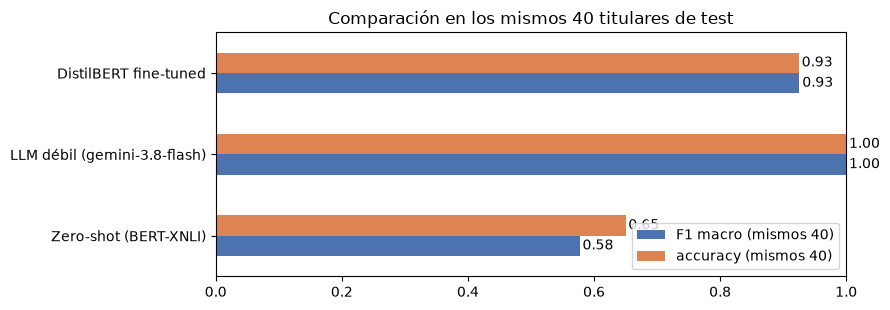

In [19]:
ax = comparativa[["F1 macro (mismos 40)", "accuracy (mismos 40)"]].plot.barh(figsize=(9, 3.2), color=["#4C72B0", "#DD8452"])
ax.set_xlim(0, 1); ax.set_title("Comparación en los mismos 40 titulares de test"); ax.set_ylabel("")
for c in ax.containers:
    ax.bar_label(c, fmt="%.2f", padding=2)
plt.tight_layout(); plt.show()

### ¿Cuál usar en un entorno real?

| Criterio | Zero-shot | LLM (Gemini) | DistilBERT fine-tuned |
|---|---|---|---|
| **Precisión** (F1 macro) | 0.58 — insuficiente | **0.97** — la mejor | 0.92 — muy buena |
| **Costo computacional** | Bajo, pero hace 4 pasadas del modelo por titular (una por categoría) | Cero local, pero se paga por token y hay cuota en el plan gratuito | Entrenar: ≈3 min en CPU, una sola vez. Usar: una pasada por titular |
| **Latencia** | ≈300–350 ms/titular | ≈370 ms/titular en lote (varios segundos por llamada) y depende de la red | **≈40–60 ms/titular** (varía entre corridas) |
| **Otros** | Sin datos ni entrenamiento | Requiere internet, envía los textos a un tercero, el modelo puede cambiar o retirarse (como pasó con `gemini-2.5-flash`) | Local, privado, determinista y bajo nuestro control |

**Recomendación: usar el DistilBERT fine-tuned en producción, y el LLM como anotador fuera de línea.**

- El fine-tuned pierde ≈5 puntos frente al LLM, pero es **≈6 a 9 veces más rápido**, **no tiene costo por consulta**,
  funciona sin internet y siempre da la misma respuesta. Para un sistema que clasifica miles de noticias al día,
  eso pesa más que la diferencia de precisión (que además es poco robusta con solo 61 noticias de test).
- El LLM se aprovecha donde mejor rinde: **generar etiquetas de entrenamiento** baratas (este experimento lo
  confirma: 95 % de acuerdo en la auditoría humana) y re-etiquetar periódicamente noticias nuevas para
  re-entrenar el modelo cuando cambien los temas de actualidad.
- Mejora posible: un esquema **híbrido**, donde el modelo local resuelve todo y solo los titulares con baja
  probabilidad (típicamente los de la frontera política/economía) se envían al LLM.
- El zero-shot queda solo para un prototipo rápido cuando todavía no hay ninguna etiqueta.